# In-loop photodiode gain and LCVR power stabilisation

Compare two PDA36A2 analogue gain settings at the **same mean laser power, Moku input range and loop response**. Increasing the PDA gain makes a given change in laser power produce more voltage before the Moku digitises it. The same Moku voltage noise then represents a smaller fractional power error, so the feedback injects less real power noise.

The example uses illustrative spectra and an integral loop with **5 Hz unity gain**. It omits detailed LCVR dynamics, PDA noise and changes in optical transmission between the pickoff and the cell. Edit the parameters and rerun all cells to explore the model. Requires NumPy and Matplotlib.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Editable settings
pda_gain_step_db = 10.0
in_loop_optical_dc_v = 1.0      # Dark-subtracted DC at the original PDA gain
out_loop_optical_dc_v = 1.0     # Dark-subtracted DC on the witness detector
unity_gain_hz = 5.0
free_running_asd_at_1hz = 60e-6  # Fractional laser power ASD [1/√Hz]
moku_asd_at_1hz = 30e-6         # In-loop Moku input noise ASD [V/√Hz]
witness_asd_at_1hz = 18e-6      # Out-of-loop electronics ASD [V/√Hz]

gain_factor = 10 ** (pda_gain_step_db / 20)
higher_gain_dc_v = in_loop_optical_dc_v * gain_factor

print(f"PDA voltage gain factor: {gain_factor:.3f}×")
print(f"In-loop optical DC: {in_loop_optical_dc_v:.3f} V → {higher_gain_dc_v:.3f} V")
print(f"To preserve the loop response, multiply the controller gain by {1 / gain_factor:.3f}.")

PDA voltage gain factor: 3.162×
In-loop optical DC: 1.000 V → 3.162 V
To preserve the loop response, multiply the controller gain by 0.316.


## Noise that reaches the laser

For open-loop gain $L(f)=f_u/(jf)$, the free-running noise couples through $|1/(1+L)|$. The in-loop Moku voltage noise couples to the actual laser power through $|L/(1+L)|$ after conversion to fractional units by dividing by the in-loop optical DC voltage $V_{\rm PD}$.

$$
A_{\rm locked}^2 =
\left|\frac{1}{1+L}\right|^2 A_{\rm free}^2
+
\left|\frac{L}{1+L}\right|^2
\left(\frac{A_{\rm Moku}}{V_{\rm PD}}\right)^2.
$$

Independent noise contributions add in quadrature. The witness detector adds its own independent noise to $A_{\rm locked}$. Its readout settings are held fixed in both cases.

In [2]:
def noise_model(frequency_hz, detector_dc_v):
    """Return fractional power ASDs for the laser and witness at positive frequencies."""
    # Illustrative 1/f PSDs, so each ASD scales as 1/√f.
    shape = 1 / np.sqrt(frequency_hz)
    loop_gain = unity_gain_hz / (1j * frequency_hz)

    free = free_running_asd_at_1hz * shape
    residual_free = free / np.abs(1 + loop_gain)
    injected_moku = (
        np.abs(loop_gain / (1 + loop_gain))
        * moku_asd_at_1hz * shape / detector_dc_v
    )
    locked = np.hypot(residual_free, injected_moku)
    witness_floor = witness_asd_at_1hz * shape / out_loop_optical_dc_v

    return {
        "free": free,
        "residual_free": residual_free,
        "injected_moku": injected_moku,
        "locked": locked,
        "witness_floor": witness_floor,
        "witness": np.hypot(locked, witness_floor),
    }


original_at_1hz = noise_model(1.0, in_loop_optical_dc_v)
higher_at_1hz = noise_model(1.0, higher_gain_dc_v)
print(f"{'ASD at 1 Hz [ppm/√Hz]':36} {'Original gain':>14} {'Changed gain':>14}")
for label, key in [
    ("Moku contribution to laser noise", "injected_moku"),
    ("Actual stabilised laser noise", "locked"),
    ("Out-of-loop measured noise", "witness"),
]:
    print(f"{label:36} {original_at_1hz[key] * 1e6:14.1f} {higher_at_1hz[key] * 1e6:14.1f}")

ASD at 1 Hz [ppm/√Hz]                 Original gain   Changed gain
Moku contribution to laser noise               29.4            9.3
Actual stabilised laser noise                  31.7           15.0
Out-of-loop measured noise                     36.4           23.4


## Compare the injected Moku noise at the two PDA gains

These curves show only the Moku contribution to the modelled optical noise. The higher PDA gain increases the detector voltage for a given optical fluctuation. At fixed loop response, the injected fractional ASD falls by the PDA voltage-gain factor at every frequency.

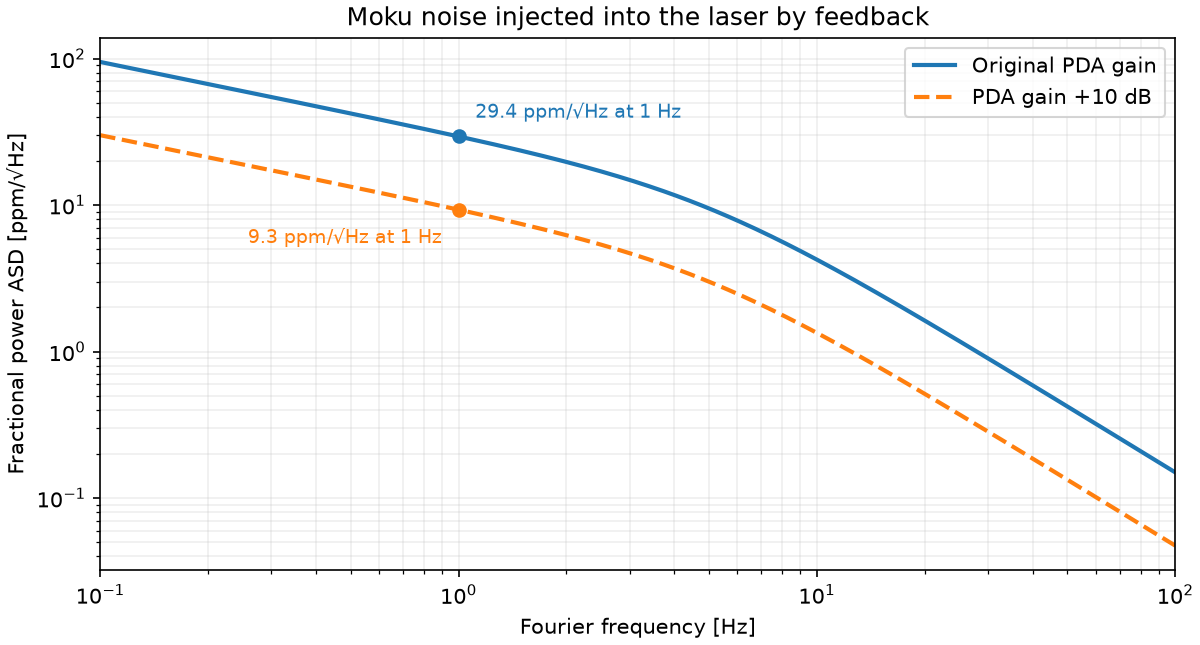

In [3]:
injection_frequency = np.geomspace(0.1, 100, 501)
fig_injection, ax_injection = plt.subplots(figsize=(8, 4.3), layout="constrained")

for detector_dc_v, colour, linestyle, label, offset, alignment in [
    (in_loop_optical_dc_v, "tab:blue", "-", "Original PDA gain", (8, 9), "left"),
    (higher_gain_dc_v, "tab:orange", "--", f"PDA gain {pda_gain_step_db:+g} dB", (-8, -16), "right"),
]:
    injected_asd = noise_model(injection_frequency, detector_dc_v)["injected_moku"] * 1e6
    injected_1hz = noise_model(1.0, detector_dc_v)["injected_moku"] * 1e6
    ax_injection.loglog(
        injection_frequency, injected_asd, linestyle,
        color=colour, linewidth=2, label=label,
    )
    ax_injection.plot(1, injected_1hz, "o", color=colour)
    ax_injection.annotate(
        f"{injected_1hz:.1f} ppm/√Hz at 1 Hz",
        (1, injected_1hz), xytext=offset,
        textcoords="offset points", ha=alignment, color=colour, fontsize=9,
    )

ax_injection.set(
    title="Moku noise injected into the laser by feedback",
    xlabel="Fourier frequency [Hz]",
    ylabel="Fractional power ASD [ppm/√Hz]",
    xlim=(0.1, 100),
)
ax_injection.grid(True, which="both", alpha=0.2)
ax_injection.legend(loc="upper right")
plt.show()

## Modelled laser noise and witness reading

**Left:** The solid curves predict the actual optical noise at the controlled pickoff. They include residual free-running noise and the injected Moku contribution shown above.

**Right:** The solid curves predict what the out-of-loop photodiode would report after its own readout noise is added in quadrature. In the lab, the out-of-loop detector is the independent check on the model. Its beam-blocked floor sets how far the optical noise can be resolved.

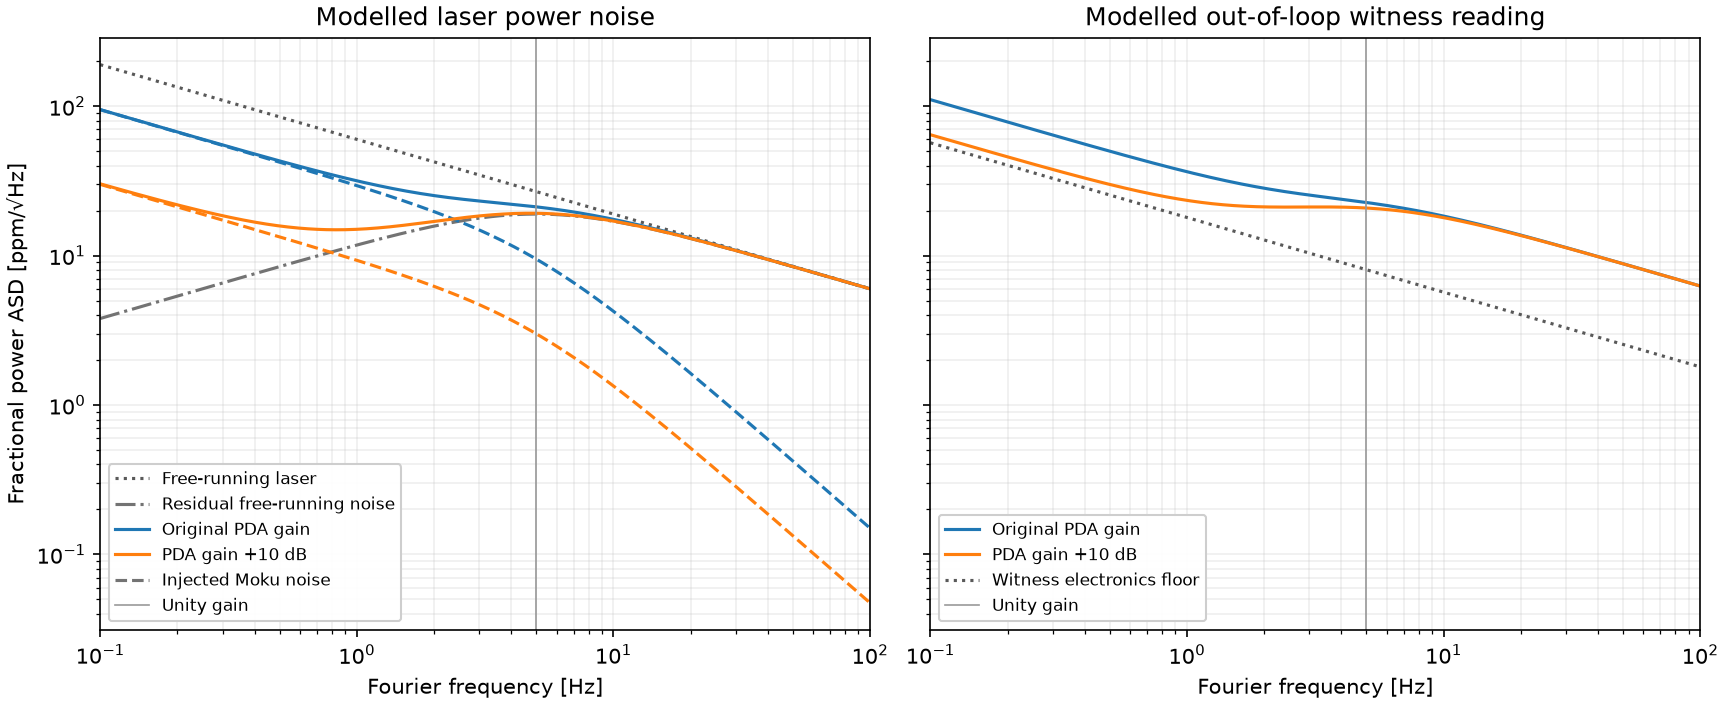

In [4]:
frequency = np.geomspace(0.1, 100, 501)
original = noise_model(frequency, in_loop_optical_dc_v)
higher_gain = noise_model(frequency, higher_gain_dc_v)

fig, (ax_laser, ax_witness) = plt.subplots(
    1, 2, figsize=(11.5, 4.7), sharey=True, layout="constrained"
)

ax_laser.loglog(frequency, original["free"] * 1e6, ":", color="0.35",
                label="Free-running laser")
ax_laser.loglog(frequency, original["residual_free"] * 1e6, "-.", color="0.45",
                label="Residual free-running noise")
for case, colour, label in [
    (original, "tab:blue", "Original PDA gain"),
    (higher_gain, "tab:orange", f"PDA gain {pda_gain_step_db:+g} dB"),
]:
    ax_laser.loglog(frequency, case["locked"] * 1e6, color=colour, label=label)
    ax_laser.loglog(frequency, case["injected_moku"] * 1e6, "--", color=colour)
    ax_witness.loglog(frequency, case["witness"] * 1e6, color=colour, label=label)

ax_laser.plot([], [], "--", color="0.45", label="Injected Moku noise")
ax_witness.loglog(frequency, original["witness_floor"] * 1e6, ":",
                  color="0.35", label="Witness electronics floor")
ax_laser.set(title="Modelled laser power noise", ylabel="Fractional power ASD [ppm/√Hz]")
ax_witness.set(title="Modelled out-of-loop witness reading")

for ax in (ax_laser, ax_witness):
    ax.axvline(unity_gain_hz, color="0.6", linewidth=0.8, label="Unity gain")
    ax.set(xlabel="Fourier frequency [Hz]", xlim=(0.1, 100))
    ax.grid(True, which="both", alpha=0.20)
    ax.legend(fontsize=8, loc="lower left", framealpha=0.95)

plt.show()

## Compare with your measurement

- **In loop.** After changing PDA gain, set the PID to the voltage at the original optical power. Scale the controller gain by the inverse of the PDA gain change and check the loop response. On the 10 Vpp range, check that the actual PDA voltage, including its offset and excursions, stays within ±5 V.
- **Out of loop.** Keep the witness readout settings fixed. Divide its voltage ASD and its beam-blocked ASD by the same dark-subtracted witness DC voltage to express both in fractional units. The solid curves can approach the witness floor even as the actual laser gets quieter.
- **At the cell.** To include power fluctuations from the delivery fibre, monitor the beam after the fibre and close to the vapour cell.

## DC subtraction before the Moku

Keep the PDA gain and mean optical power fixed. Connect the PDA output to the instrumentation amplifier's positive input and a buffered DC reference to its negative input. The reference is set close to the **raw** PDA voltage at the desired optical power, including any dark offset. The amplifier sends the amplified difference to the Moku's DC-coupled input. This is differential-input subtraction. An amplifier's REF pin, where present, typically sets an output offset. [AD8421 datasheet, Reference Terminal](https://www.analog.com/media/en/technical-documentation/data-sheets/AD8421.pdf)

Let $x=\delta P/P_0$ and $D=V_{\rm PD,optical}$ be the **dark-subtracted PDA DC voltage before the amplifier**. Then a fractional fluctuation $x$ produces $Dx$ volts at the PDA output. Although the amplified difference can sit close to zero DC, its optical response is $GD$ volts per unit fractional power. Use $GD$ to refer the Moku noise back to fractional optical units.

At the Moku input, the small-signal error voltage is

$$
\delta v_{\rm err}=G\bigl(Dx+n_{\rm amp}-n_{\rm ref}+k_T\,\delta T\bigr)+n_{\rm Moku}.
$$

Here $n_{\rm amp}$ is amplifier noise referred to its differential input and $n_{\rm ref}$ is noise at the reference input, including its buffer or divider. $n_{\rm Moku}$ is added after the amplifier. For the same open-loop response $L$ in both configurations, feedback gives

$$
x=\frac{x_{\rm free}}{1+L}
-\frac{L}{1+L}\left(
\frac{n_{\rm amp}-n_{\rm ref}+k_T\,\delta T}{D}
+\frac{n_{\rm Moku}}{GD}\right).
$$

The extra analogue gain divides the Moku's **injected fractional ASD** by $G$. Amplifier input noise and reference noise enter before the gain and retain their coupling to the optical power. Within the loop bandwidth the laser follows slow reference drift. For example, a $1\,\mu\mathrm V$ reference increase commands a $1$ ppm optical power increase when $D=1\,\mathrm V$, with the amplifier temperature held fixed.

### Temperature drift and gain

For a common electronics temperature variation, this example uses

$$
k_T=\frac{dV_{\rm os}}{dT}-\frac{dV_{\rm ref}}{dT}
+V_{\rm diff,0}\,\frac{1}{G}\frac{dG}{dT}.
$$

$V_{\rm os}$ is the amplifier's equivalent input offset and $V_{\rm diff,0}$ is the nominal input difference, including static amplifier offset. The three terms add with their signs because they respond to the same temperature change. A small input difference reduces the effect of amplifier gain drift. The example treats random amplifier noise, reference noise, Moku noise and temperature fluctuations as independent of one another.

All new circuit noise levels and temperature coefficients below are illustrative. The model assumes flat analogue gain over the plotted band and omits PDA noise and PDA thermal drift in both configurations. Its headroom calculation covers the Moku input only. The amplifier's own output swing and input common-mode range depend on its supply and part.

In [5]:
# Run the original settings and noise-model cells above first.
# The direct and amplified cases use the original PDA gain and mean optical power.
analogue_gain = 20.0
pda_dark_offset_v = 15e-3
input_mismatch_v = 5e-3     # Raw PDA DC minus reference, including any static input offset
peak_fractional_excursion = 0.05
moku_peak_range_v = 5.0    # 10 Vpp input range

amp_white_asd_v = 25e-9    # V/√Hz, total amplifier noise referred to its input
amp_flicker_corner_hz = 1.0
ref_white_asd_v = 200e-9   # V/√Hz at the amplifier's negative input
ref_flicker_corner_hz = 2.0

amp_offset_tempco_v_per_k = 0.5e-6
ref_tempco_v_per_k = 2.0e-6  # Signed drift at the actual subtraction voltage
amp_gain_tempco_per_k = 20e-6
temperature_asd_at_1hz = 0.03  # K/√Hz, illustrative electronics temperature spectrum
temperature_corner_hz = 0.1
example_temperature_change_k = 1.0

optical_dc_v = in_loop_optical_dc_v
raw_pda_dc_v = optical_dc_v + pda_dark_offset_v
reference_setpoint_v = raw_pda_dc_v - input_mismatch_v
moku_output_dc_v = analogue_gain * input_mismatch_v
direct_peak_v = abs(raw_pda_dc_v) + optical_dc_v * peak_fractional_excursion
amplified_peak_v = abs(moku_output_dc_v) + (
    analogue_gain * optical_dc_v * peak_fractional_excursion
)
input_thermal_slope_v_per_k = (
    amp_offset_tempco_v_per_k - ref_tempco_v_per_k
    + input_mismatch_v * amp_gain_tempco_per_k
)

print(f"Raw PDA DC: {raw_pda_dc_v:.3f} V")
print(f"Reference setpoint (assuming zero static amp offset): {reference_setpoint_v:.3f} V")
print(f"Residual DC at Moku input: {moku_output_dc_v:+.3f} V")
print(f"Optical voltage sensitivity before digitising: "
      f"{optical_dc_v:g} → {analogue_gain * optical_dc_v:g} V per unit fractional power")
print(f"Controller gain multiplier to keep the same loop response: {1 / analogue_gain:.3g}")
print(f"Estimated peak at Moku, direct / with amp: {direct_peak_v:.2f} / "
      f"{amplified_peak_v:.2f} V (limit ±{moku_peak_range_v:g} V)")
if max(direct_peak_v, amplified_peak_v) >= moku_peak_range_v:
    print("At least one configuration exceeds the specified Moku input range.")
slow_drift_ppm = (
    -input_thermal_slope_v_per_k * example_temperature_change_k / optical_dc_v * 1e6
)
print(f"Slow {example_temperature_change_k:+g} K electronics change → "
      f"{slow_drift_ppm:+.2f} ppm real optical power change in this model.")

Raw PDA DC: 1.015 V
Reference setpoint (assuming zero static amp offset): 1.010 V
Residual DC at Moku input: +0.100 V
Optical voltage sensitivity before digitising: 1 → 20 V per unit fractional power
Controller gain multiplier to keep the same loop response: 0.05
Estimated peak at Moku, direct / with amp: 1.06 / 1.10 V (limit ±5 V)
Slow +1 K electronics change → +1.40 ppm real optical power change in this model.


In [6]:
def analogue_subtraction_noise(frequency_hz):
    '''Return one-sided fractional ASDs for the laser and its witness, before and after DC subtraction.'''
    frequency_hz = np.asarray(frequency_hz, dtype=float)
    if np.any(frequency_hz <= 0):
        raise ValueError("Use positive Fourier frequencies.")

    direct = noise_model(frequency_hz, optical_dc_v)
    loop_gain = unity_gain_hz / (1j * frequency_hz)
    sensor_coupling = np.abs(loop_gain / (1 + loop_gain)) / optical_dc_v

    amp_asd_v = amp_white_asd_v * np.sqrt(1 + amp_flicker_corner_hz / frequency_hz)
    reference_asd_v = ref_white_asd_v * np.sqrt(1 + ref_flicker_corner_hz / frequency_hz)
    # A simple temperature spectrum with a low-frequency plateau, normalised at 1 Hz.
    temperature_asd = (
        temperature_asd_at_1hz * np.hypot(1.0, temperature_corner_hz)
        / np.hypot(frequency_hz, temperature_corner_hz)
    )

    injected = {
        "moku": direct["injected_moku"] / analogue_gain,
        "amplifier": sensor_coupling * amp_asd_v,
        "reference": sensor_coupling * reference_asd_v,
        "temperature": sensor_coupling * abs(input_thermal_slope_v_per_k) * temperature_asd,
    }
    locked = np.sqrt(direct["residual_free"]**2 + sum(asd**2 for asd in injected.values()))

    return direct, {
        **injected,
        "locked": locked,
        "witness": np.hypot(locked, direct["witness_floor"]),
    }


direct_at_1hz, amplified_at_1hz = analogue_subtraction_noise(1.0)
print("Fractional power ASD at 1 Hz [ppm/√Hz]")
for label, value in [
    ("Moku contribution, direct PDA", direct_at_1hz["injected_moku"]),
    ("Moku contribution, with amp", amplified_at_1hz["moku"]),
    ("Amplifier input noise", amplified_at_1hz["amplifier"]),
    ("Reference input noise", amplified_at_1hz["reference"]),
    ("Electronics temperature fluctuations", amplified_at_1hz["temperature"]),
    ("Residual free-running laser noise", direct_at_1hz["residual_free"]),
    ("Actual laser, direct / with amp", (direct_at_1hz["locked"], amplified_at_1hz["locked"])),
    ("Witness reading, direct / with amp", (direct_at_1hz["witness"], amplified_at_1hz["witness"])),
]:
    formatted = " / ".join(f"{asd * 1e6:.3f}" for asd in np.atleast_1d(value))
    print(f"  {label:<40} {formatted}")

Fractional power ASD at 1 Hz [ppm/√Hz]
  Moku contribution, direct PDA            29.417
  Moku contribution, with amp              1.471
  Amplifier input noise                    0.035
  Reference input noise                    0.340
  Electronics temperature fluctuations     0.041
  Residual free-running laser noise        11.767
  Actual laser, direct / with amp          31.684 / 11.864
  Witness reading, direct / with amp       36.440 / 21.558


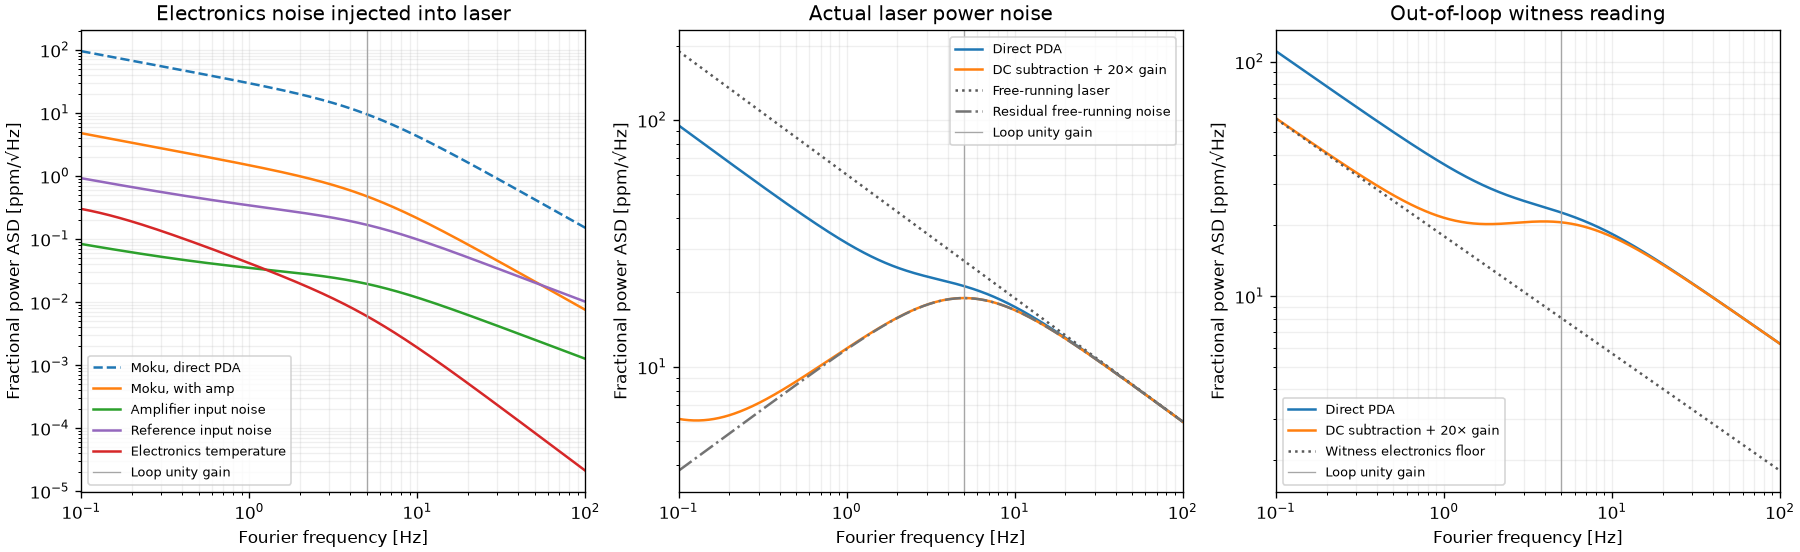

In [7]:
subtraction_frequency = np.geomspace(0.1, 100, 501)
direct, amplified = analogue_subtraction_noise(subtraction_frequency)
fig_subtraction, (ax_elec, ax_optical, ax_monitor) = plt.subplots(
    1, 3, figsize=(15, 4.6), layout="constrained",
)
if hasattr(fig_subtraction.canvas, "header_visible"):
    fig_subtraction.canvas.header_visible = False

ax_elec.loglog(subtraction_frequency, 1e6 * direct["injected_moku"], "--",
               color="tab:blue", label="Moku, direct PDA")
for key, label, colour in [
    ("moku", "Moku, with amp", "tab:orange"),
    ("amplifier", "Amplifier input noise", "tab:green"),
    ("reference", "Reference input noise", "tab:purple"),
    ("temperature", "Electronics temperature", "tab:red"),
]:
    ax_elec.loglog(subtraction_frequency, 1e6 * amplified[key], color=colour, label=label)

for ax, key in [(ax_optical, "locked"), (ax_monitor, "witness")]:
    ax.loglog(subtraction_frequency, 1e6 * direct[key], color="tab:blue", label="Direct PDA")
    ax.loglog(subtraction_frequency, 1e6 * amplified[key], color="tab:orange",
              label=f"DC subtraction + {analogue_gain:g}× gain")

ax_optical.loglog(subtraction_frequency, 1e6 * direct["free"], ":", color="0.35",
                  label="Free-running laser")
ax_optical.loglog(subtraction_frequency, 1e6 * direct["residual_free"], "-.", color="0.45",
                  label="Residual free-running noise")
ax_monitor.loglog(subtraction_frequency, 1e6 * direct["witness_floor"], ":", color="0.35",
                  label="Witness electronics floor")

ax_elec.set_title("Electronics noise injected into laser")
ax_optical.set_title("Actual laser power noise")
ax_monitor.set_title("Out-of-loop witness reading")
for ax in (ax_elec, ax_optical, ax_monitor):
    ax.axvline(unity_gain_hz, color="0.65", linewidth=0.8, label="Loop unity gain")
    ax.set(xlabel="Fourier frequency [Hz]", ylabel="Fractional power ASD [ppm/√Hz]",
           xlim=(0.1, 100))
    ax.grid(True, which="both", alpha=0.20)
    ax.legend(fontsize=8)

plt.show()

### Compare with your circuit

- **Gain.** Change the analogue gain and rerun the new cells. The Moku term should move by the gain ratio. Once the amplifier, reference, temperature or residual free-running terms dominate, further gain produces little improvement in that band.
- **Reference and drift.** Use the noise ASD and signed temperature coefficient at the reference voltage fed to the amplifier. Those values include the effect of the divider and buffer. The printed temperature step estimates how far the real power moves for a slow temperature change within the loop's correction range. It is a separate calculation from the noise spectrum.
- **Check the loop and witness.** Recheck loop gain and actuator range when you change the analogue gain. Keep the witness electronics fixed when comparing the two locks. The plot labelled **Actual laser power noise** is the model prediction. The witness plot shows how much of the change the independent detector can resolve.

For RIN PSD in dBc/Hz, use $20\log_{10}(A)$ with the fractional ASD $A$ in $1/\sqrt{\mathrm{Hz}}$. If reading the plotted ASD in ppm/$\sqrt{\mathrm{Hz}}$, multiply by $10^{-6}$ before taking the logarithm.

## Allan deviation from the RIN spectrum

The earlier cells give the fractional optical power ASD $A_x(f)$, where $x=\delta P/P_0$. Square it to get the one-sided RIN PSD, $S_x(f)=A_x^2(f)$ in $\mathrm{Hz}^{-1}$. If starting from RIN in dBc/Hz, use $S_x=10^{\mathrm{RIN}_{\mathrm{dBc/Hz}}/10}$.

For a small power change at fixed beam geometry, let $K_P=d(\nu_{\rm lock}/\nu_0)/dP$ in $\mathrm{mW}^{-1}$. The light shift gives $y=\delta\nu/\nu_0=(K_P P_0)x$ and hence $S_y=(K_P P_0)^2 S_x$. Here $P_0$ is the one-way optical power at the cell, in mW. The calculation uses an instantaneous, linear light-shift response over the frequencies that contribute to the plot.

Use the ordinary Allan-variance spectral response from [Enrico's Chart](https://doi.org/10.5281/zenodo.4399218) and [Rubiola and Vernotte, Eqs. (35)–(36)](https://doi.org/10.1109/TMTT.2023.3238267):

$$
\sigma_y(\tau)=\sqrt{
\int_0^\infty S_y(f)\,2\frac{\sin^4(\pi f\tau)}{(\pi f\tau)^2}\,df
}.
$$

The same kernel applied to $S_x$ gives fractional **power** Allan deviation. Thus the clock contribution is $|K_P|P_0$ times the actual optical power Allan deviation. The out-of-loop witness curve includes its own readout noise and is only used in the power panel. The clock panel uses the modelled optical power reaching the atoms and includes only the light-shift contribution.

The defaults $P_0=30$ mW and $K_P=-4.8\times10^{-13}\,\mathrm{mW}^{-1}$ are from [Martin et al., Sec. III B and Fig. 3(a)](https://doi.org/10.1103/PhysRevApplied.9.014019), for their $1/e^2$ beam radius of about 0.66 mm. Replace these values with your operating power and measured slope. If you measure the slope in Hz/mW, divide it by the corresponding carrier frequency to get $K_P$. For a slope measured on the 778 nm laser beat, use the 778 nm optical carrier frequency.

The model is evaluated beyond the earlier display band of 0.1–100 Hz to cover the averaging times below. These curves are predictions from illustrative spectra. A measured PSD with limited low-frequency coverage cannot establish long-$\tau$ stability by itself. The kernel peaks near $f=0.45/\tau$, so the 100 s point relies strongly on noise around 4.5 mHz. The temperature term is the model's random temperature fluctuation. A steady temperature ramp would add a separate drift contribution.

In [8]:
def allan_deviation_from_psd(frequency_hz, one_sided_psd, averaging_times_s):
    """Integrate the ordinary Allan kernel against a one-sided PSD on a positive frequency grid.

    frequency_hz is increasing, one_sided_psd has frequency on its last axis,
    and averaging_times_s is a 1D array of positive averaging times. The
    result has the PSD's leading dimensions followed by the averaging-time axis.
    """
    frequency_hz = np.asarray(frequency_hz, dtype=float)
    psd = np.asarray(one_sided_psd, dtype=float)
    averaging_times_s = np.asarray(averaging_times_s, dtype=float)
    frequency_steps = np.diff(frequency_hz)
    if frequency_hz.size < 2 or frequency_hz[0] <= 0 or np.any(frequency_steps <= 0):
        raise ValueError("Use at least two strictly increasing positive frequencies.")
    if psd.shape[-1] != frequency_hz.size or np.any(psd < 0):
        raise ValueError("Use a nonnegative PSD with one value per frequency.")
    if np.any(averaging_times_s <= 0):
        raise ValueError("Use positive averaging times.")

    # Trapezoidal weights account for the unequal spacing of the frequency grid.
    weights = np.empty_like(frequency_hz)
    weights[0] = frequency_steps[0] / 2
    weights[-1] = frequency_steps[-1] / 2
    weights[1:-1] = (frequency_steps[:-1] + frequency_steps[1:]) / 2
    variance = np.empty(psd.shape[:-1] + averaging_times_s.shape)
    for i, tau in enumerate(averaging_times_s):
        u = frequency_hz * tau
        allan_kernel = 2 * (np.sin(np.pi * u) * np.sinc(u))**2
        variance[..., i] = np.sum(psd * (weights * allan_kernel), axis=-1)
    return np.sqrt(variance)

|K_P| P_0 = 1.44e-11
Clock ADEV due to power fluctuations (model)
 Tau [s]     Direct PDA   DC subtraction
       1      5.149e-16        9.631e-17
      10      5.087e-16        2.846e-17
     100      5.086e-16        2.592e-17


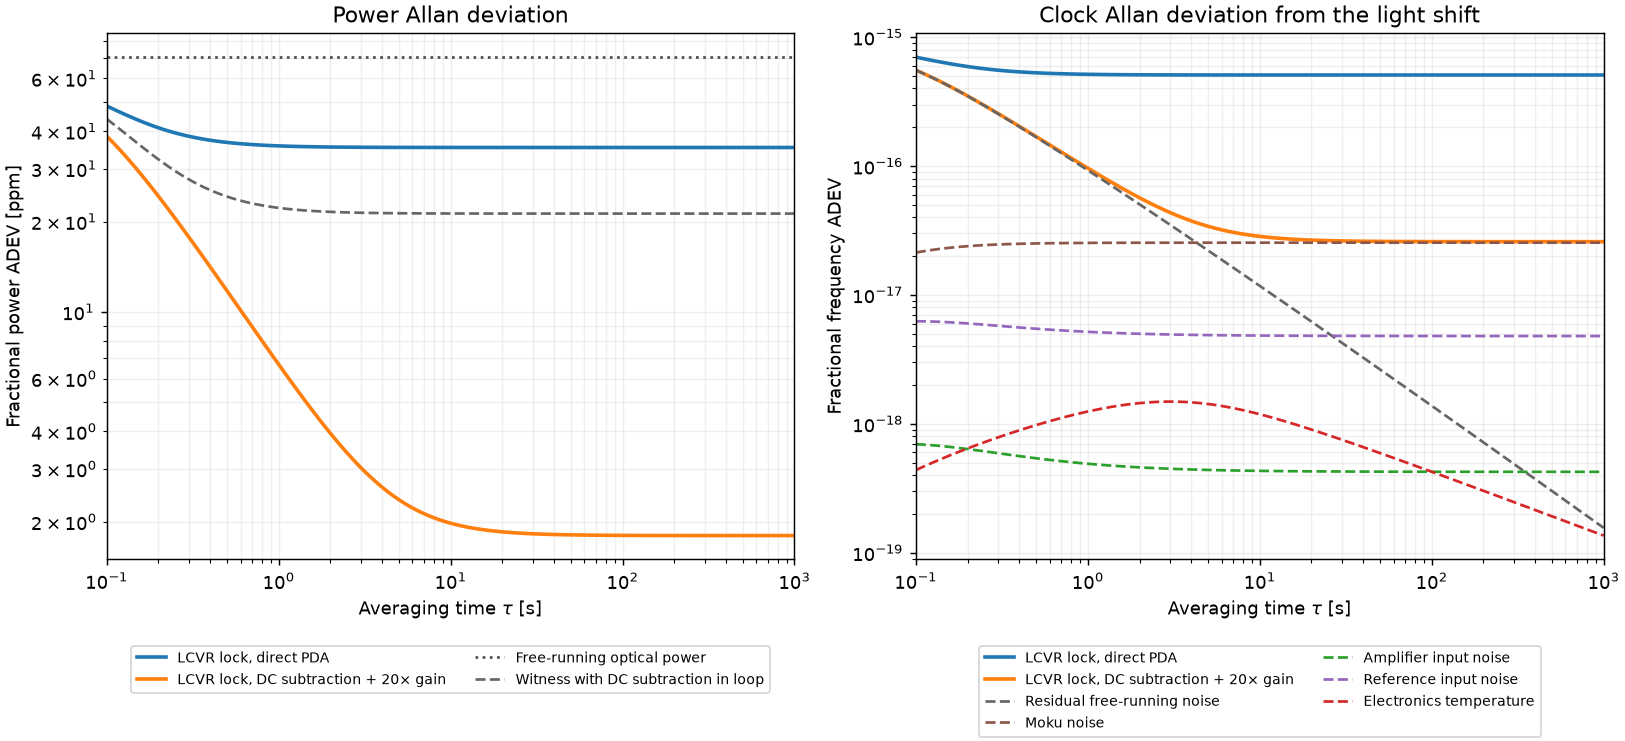

In [9]:
# Run the preceding circuit model before this cell.
cell_power_mw = 30.0
fractional_light_shift_per_mw = -4.8e-13
light_shift_per_fractional_power = abs(fractional_light_shift_per_mw * cell_power_mw)

allan_times_s = np.geomspace(0.1, 1_000, 121)
allan_frequency_hz = np.geomspace(1e-6, 1e4, 30_001)
allan_direct, allan_amplified = analogue_subtraction_noise(allan_frequency_hz)

asd_curves = {
    "free": allan_direct["free"],
    "direct": allan_direct["locked"],
    "amplified": allan_amplified["locked"],
    "witness": allan_amplified["witness"],
    "residual_free": allan_direct["residual_free"],
    "moku": allan_amplified["moku"],
    "amplifier": allan_amplified["amplifier"],
    "reference": allan_amplified["reference"],
    "temperature": allan_amplified["temperature"],
}
power_adev = dict(zip(asd_curves, allan_deviation_from_psd(
    allan_frequency_hz, np.stack(list(asd_curves.values()))**2, allan_times_s,
)))

fig_adev, (ax_power_adev, ax_clock_adev) = plt.subplots(
    1, 2, figsize=(12.5, 5.7), layout="constrained",
)
if hasattr(fig_adev.canvas, "header_visible"):
    fig_adev.canvas.header_visible = False

for key, label, colour in [
    ("direct", "LCVR lock, direct PDA", "tab:blue"),
    ("amplified", f"LCVR lock, DC subtraction + {analogue_gain:g}× gain", "tab:orange"),
]:
    ax_power_adev.loglog(allan_times_s, 1e6 * power_adev[key], color=colour,
                         linewidth=2, label=label)
    ax_clock_adev.loglog(allan_times_s, light_shift_per_fractional_power * power_adev[key],
                         color=colour, linewidth=2, label=label)

ax_power_adev.loglog(allan_times_s, 1e6 * power_adev["free"], ":", color="0.3",
                     label="Free-running optical power")
ax_power_adev.loglog(allan_times_s, 1e6 * power_adev["witness"], "--", color="0.4",
                     label="Witness with DC subtraction in loop")

for key, label, colour in [
    ("residual_free", "Residual free-running noise", "0.4"),
    ("moku", "Moku noise", "tab:brown"),
    ("amplifier", "Amplifier input noise", "tab:green"),
    ("reference", "Reference input noise", "tab:purple"),
    ("temperature", "Electronics temperature", "tab:red"),
]:
    ax_clock_adev.loglog(allan_times_s, light_shift_per_fractional_power * power_adev[key],
                         "--", color=colour, label=label)

ax_power_adev.set(title="Power Allan deviation", ylabel="Fractional power ADEV [ppm]")
ax_clock_adev.set(title="Clock Allan deviation from the light shift",
                  ylabel="Fractional frequency ADEV")
for ax in (ax_power_adev, ax_clock_adev):
    ax.set(xlabel=r"Averaging time $\tau$ [s]", xlim=(allan_times_s[0], allan_times_s[-1]))
    ax.grid(True, which="both", alpha=0.20)
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)

print(f"|K_P| P_0 = {light_shift_per_fractional_power:.3g}")
print("Clock ADEV due to power fluctuations (model)")
print(f"{'Tau [s]':>8} {'Direct PDA':>14} {'DC subtraction':>16}")
for tau in (1.0, 10.0, 100.0):
    i = np.argmin(np.abs(np.log(allan_times_s / tau)))
    print(f"{allan_times_s[i]:8g} "
          f"{light_shift_per_fractional_power * power_adev['direct'][i]:14.3e} "
          f"{light_shift_per_fractional_power * power_adev['amplified'][i]:16.3e}")

plt.show()